# Fase 4 — Modelagem

**Projeto:** Detecção de fraude em sinistros de automóvel — Quilha Seguros
**Semente:** `42` · **Holdout:** agosto/2026 · **Capacidade:** 900 perícias/mês

Este notebook integra as Partes 0 a 6. As buscas custosas das Partes 3 a 5 são
consumidas das tabelas versionadas, em vez de serem repetidas a cada execução.
A Regra Atual tem sua CV revalidada no treino porque o run original não persistiu
as métricas dos folds. Ao final, o campeão é reajustado no treino completo,
avaliado uma vez no holdout, salvo para o aplicativo e verificado após recarga.

MLflow usa DagsHub quando há credenciais e SQLite local quando não há; nenhuma
célula exige token para concluir.

In [1]:
# =============================================================================
# Raiz do projeto, imports e reprodutibilidade
# =============================================================================
from pathlib import Path
import sys
import warnings

import numpy as np
import pandas as pd
from sklearn.base import clone
from IPython.display import Image, Markdown, display

SEED = 42
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="Saving scikit-learn models in the pickle or cloudpickle format")
warnings.filterwarnings("ignore", message="Failed to resolve installed pip version")
warnings.filterwarnings("ignore", message="Credenciais do MLflow ausentes")


def localizar_raiz(inicio: Path) -> Path:
    """Sobe diretórios até localizar o pyproject.toml da raiz."""
    for pasta in [inicio.resolve(), *inicio.resolve().parents]:
        if (pasta / "pyproject.toml").exists():
            return pasta
    raise FileNotFoundError("Raiz do projeto não encontrada (pyproject.toml ausente).")


RAIZ = localizar_raiz(Path.cwd())
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

from quilha.dados import DATA_CORTE, carregar_base_crua
from quilha.mlops import contexto_run, credenciais_presentes, nome_run
from quilha.modelagem import (
    ALIAS_CAMPEAO,
    CAPACIDADE_MENSAL,
    LIMIAR_CORTE_TEORICO,
    NOME_MODELO_REGISTRADO,
    SEED as SEED_MODELAGEM,
    RegraAtualQuilha,
    ajustar_candidato,
    calcular_metricas_holdout,
    carregar_treino_teste,
    executar_validacao_cruzada,
    montar_ranking_candidatos,
    resumir_validacao_cruzada,
    separar_entrada_alvo,
)
from quilha.pipeline import CAMINHO_PIPELINE, carregar_pipeline, salvar_pipeline
from quilha.pipeline import construir_pipeline

assert SEED == SEED_MODELAGEM
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
print("Raiz do projeto localizada pelo pyproject.toml.")
print(f"SEED={SEED} | k holdout={CAPACIDADE_MENSAL} | corte teórico={LIMIAR_CORTE_TEORICO:.4%}")
print(f"Credenciais MLOps presentes: {credenciais_presentes()}")
if not credenciais_presentes():
    print("Sem credenciais remotas: as runs usam o fallback local em mlflow.db.")

Raiz do projeto localizada pelo pyproject.toml.
SEED=42 | k holdout=900 | corte teórico=3.2258%
Credenciais MLOps presentes: False
Sem credenciais remotas: as runs usam o fallback local em mlflow.db.


## 1. Revalidar a Regra Atual pela CV oficial

Os outros cinco baselines já têm seus resultados de cinco folds registrados no
MLflow e congelados em `reports/tabelas/parte2_cv_base_mlflow.csv`. A Regra Atual
não tinha métricas CV persistidas; recalculamos somente essa linha usando os
mesmos cinco folds estratificados do treino e `k=720`. O holdout não participa.

In [2]:
base_crua_treino = carregar_base_crua()
mascara_treino = pd.to_datetime(base_crua_treino["data_abertura"]) < DATA_CORTE
base_treino_cv = base_crua_treino.loc[mascara_treino].copy()
X_treino_cv, y_treino_cv = separar_entrada_alvo(base_treino_cv)

with contexto_run(
    nome=nome_run("regra_atual_quilha", "parte2_cv_revalidacao", SEED),
    parametros={
        "familia_modelo": "regra_atual_quilha",
        "seed": SEED,
        "n_splits_cv": 5,
        "k_fold": 720,
        "origem": "revalidacao_integracao_parte6",
    },
    tags={"fase": "4", "parte": "2", "modelo": "regra_atual_quilha"},
) as registro_cv_regra:
    tabela_cv_regra, _ = executar_validacao_cruzada(
        estimador=RegraAtualQuilha(),
        X_treino=X_treino_cv,
        y_treino=y_treino_cv,
        seed=SEED,
        return_estimator=False,
    )
    resumo_cv_regra = resumir_validacao_cruzada(tabela_cv_regra)
    registro_cv_regra.log_metricas(resumo_cv_regra, prefixo="cv_")
    registro_cv_regra.log_json(
        tabela_cv_regra.to_dict(orient="records"),
        "tabela_cv_regra_atual.json",
    )
    pipeline_regra = construir_pipeline(modelo=clone(RegraAtualQuilha()))
    pipeline_regra.fit(X_treino_cv, y_treino_cv)
    registro_cv_regra.log_pipeline(pipeline_regra, X_treino_cv.head(1))

id_run_regra = registro_cv_regra.run_id or "MLflow indisponível"
linha_cv_regra = {
    "familia_modelo": "regra_atual_quilha",
    **resumo_cv_regra,
    "run_id_mlflow": id_run_regra,
}
tabela_cv_base = pd.read_csv(RAIZ / "reports" / "tabelas" / "parte2_cv_base_mlflow.csv")
tabela_cv_modelos = pd.concat(
    [tabela_cv_base, pd.DataFrame([linha_cv_regra])],
    ignore_index=True,
).sort_values("resultado_k_cv_media", ascending=False)
caminho_cv = RAIZ / "reports" / "tabelas" / "parte2_cv_seis_modelos.csv"
tabela_cv_modelos.to_csv(caminho_cv, index=False)

print(f"Treino usado na CV: {len(X_treino_cv):,} linhas; fraudes={int(y_treino_cv.sum()):,}.")
print(f"Run da revalidação da Regra Atual: {id_run_regra}")
display(tabela_cv_modelos)

2026/11/07 12:17:31 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/07 12:17:36 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Treino usado na CV: 48,096 linhas; fraudes=1,199.
Run da revalidação da Regra Atual: 8ad86787c00840d68584d9a412d57e64


,familia_modelo,k_fold,pr_auc_cv_media,pr_auc_cv_desvio,roc_auc_cv_media,roc_auc_cv_desvio,precisao_k_cv_media,precisao_k_cv_desvio,resultado_k_cv_media,resultado_k_cv_desvio,run_id_mlflow
4,lightgbm,720,0.490043,0.029556,0.932705,0.007787,0.232778,0.010467,3132920.0,163543.731155,ec9a933940f449c397385cb0026db2a1
2,random_forest,720,0.488402,0.028138,0.911854,0.015877,0.222778,0.015422,2976680.0,240957.956914,406eba1fc1a441eea5f95bebf60ed6bc
3,xgboost,720,0.465598,0.036794,0.923413,0.010503,0.222222,0.007857,2968000.0,122753.737214,793dcfb34c3f4836944bf44e505a2be9
1,decision_tree,720,0.137035,0.021086,0.673162,0.017121,0.132778,0.010328,1570520.0,161369.814402,6c03676122e3408ab9e5adc659146f12
0,dummy_prior,720,0.024929,0.000046,0.500000,0.000000,0.026111,0.005503,-96040.0,85982.399362,4030c7ba7319481a8265860a95b51922
5,regra_atual_quilha,720,0.024474,0.000171,0.487656,0.009293,0.017222,0.005693,-234920.0,88943.532649,8ad86787c00840d68584d9a412d57e64


## 2. Resultados congelados das Partes 3 a 5

A seleção prioriza Resultado Líquido@900, não acurácia. As tabelas são artefatos
das execuções já concluídas; nenhuma busca de hiperparâmetros é repetida aqui.

In [3]:
pasta_tabelas = RAIZ / "reports" / "tabelas"
vencedores_parte3 = pd.read_csv(pasta_tabelas / "parte3_vencedores_familia.csv")
amostragem_parte4 = pd.read_csv(pasta_tabelas / "parte4_amostragem.csv")
ranking_candidatos = montar_ranking_candidatos()
custo_familias = pd.read_csv(pasta_tabelas / "parte5_custo31_familias.csv")
sementes_campeao = pd.read_csv(pasta_tabelas / "parte5_sementes_campeao.csv")
ablacao = pd.read_csv(pasta_tabelas / "parte5_ablacao.csv")
calibracao = pd.read_csv(pasta_tabelas / "parte5_calibracao.csv")
casos_shap = pd.read_csv(pasta_tabelas / "parte5_shap_casos.csv")
importancia_shap = pd.read_csv(pasta_tabelas / "parte5_shap_importancia.csv")

print("Vencedores da busca e poda da Parte 3:")
display(vencedores_parte3)
print("Comparação das estratégias de amostragem da Parte 4:")
display(
    amostragem_parte4[
        [
            "familia_modelo",
            "estrategia",
            "pr_auc_holdout",
            "resultado_900_holdout",
            "tp_900_holdout",
            "fp_900_holdout",
            "fn_900_holdout",
        ]
    ].sort_values("resultado_900_holdout", ascending=False)
)
print("Top candidatos por Resultado Líquido@900:")
display(ranking_candidatos.head(10))

Vencedores da busca e poda da Parte 3:


,familia_modelo,iteracao,origem_pesos,n_folhas_holdout,k_fold,pr_auc_cv_media,pr_auc_cv_desvio,roc_auc_cv_media,roc_auc_cv_desvio,precisao_k_cv_media,precisao_k_cv_desvio,resultado_k_cv_media,resultado_k_cv_desvio,pr_auc_holdout,roc_auc_holdout,brier_holdout,precisao_900_holdout,cobertura_900_holdout,resultado_900_holdout,custo_total_900_holdout,...,fn_900_holdout,run_id,uri_modelo,param_class_weight,param_max_depth,param_min_samples_leaf,param_n_estimators,param_subsample,param_scale_pos_weight,param_reg_lambda,param_min_child_weight,param_learning_rate,param_gamma,param_colsample_bytree,param_bagging_fraction,param_feature_fraction,param_is_unbalance,param_lambda_l2,param_min_child_samples,param_num_leaves
0,decision_tree,39,sem_peso,139.000000,720,0.452752,0.030796,0.906611,0.005985,0.221944,0.009491,2963660.0,148292.154209,0.474156,0.896769,0.015780,0.201111,0.644128,3297700.0,2673300.0,...,100,e048f69c2e9e4757a6bf3c43d990d306,NaN,NaN,10.0,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,lightgbm,11,peso_39_11,NaN,720,0.519168,0.053156,0.940285,0.007845,0.237778,0.009286,3211040.0,145081.987166,0.522257,0.932059,0.087018,0.215556,0.690391,3579800.0,2382100.0,...,87,c8f552b0098d4586b0085ef5a6715448,NaN,NaN,NaN,NaN,200.0,NaN,39.11,NaN,NaN,0.03,NaN,NaN,1.0,1.0,False,10.0,50.0,15.0
2,random_forest,3,balanced,294.406667,720,0.506475,0.027271,0.936760,0.008118,0.235556,0.009139,3176320.0,142791.936047,0.507874,0.927249,0.072196,0.213333,0.683274,3536400.0,2426900.0,...,89,e7acb2dc9e194b15bd8d598cbb26e67d,NaN,balanced,NaN,20.0,300.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,xgboost,9,sem_peso,NaN,720,0.519659,0.041908,0.940794,0.006749,0.243056,0.008039,3293500.0,125597.830395,0.538556,0.936597,0.014702,0.223333,0.715302,3731700.0,2225300.0,...,80,e328a1ee316d449d924bc7feee6817ef,NaN,NaN,4.0,NaN,350.0,0.85,1.00,1.0,5.0,0.03,3.0,0.7,NaN,NaN,NaN,NaN,NaN,NaN


Comparação das estratégias de amostragem da Parte 4:


,familia_modelo,estrategia,pr_auc_holdout,resultado_900_holdout,tp_900_holdout,fp_900_holdout,fn_900_holdout
15,xgboost,controle,0.538556,3731700.0,201,699,80
17,xgboost,aleatorio_1_5,0.529416,3688300.0,199,701,82
16,xgboost,aleatorio_1_10,0.532751,3623200.0,196,704,85
7,lightgbm,aleatorio_1_10,0.515081,3601500.0,195,705,86
6,lightgbm,aleatorio_1_5,0.519489,3601500.0,195,705,86
5,lightgbm,controle,0.522257,3579800.0,194,706,87
12,random_forest,aleatorio_1_10,0.504102,3558100.0,193,707,88
11,random_forest,aleatorio_1_5,0.498816,3536400.0,192,708,89
10,random_forest,controle,0.507874,3536400.0,192,708,89
1,decision_tree,aleatorio_1_10,0.426462,3449600.0,188,712,93


Top candidatos por Resultado Líquido@900:


,origem,familia_modelo,estrategia,resultado_900_holdout,pr_auc_holdout,tp_900_holdout,fp_900_holdout,fn_900_holdout,parametros_modelo
0,parte3,xgboost,controle,3731700.0,0.538556,201,699,80,"{'max_depth': 4, 'n_estimators': 350, 'subsamp..."
1,parte4,xgboost,aleatorio_1_5,3688300.0,0.529416,199,701,82,"{'max_depth': 4, 'n_estimators': 350, 'subsamp..."
2,parte4,xgboost,aleatorio_1_10,3623200.0,0.532751,196,704,85,"{'max_depth': 4, 'n_estimators': 350, 'subsamp..."
3,parte4,lightgbm,aleatorio_1_5,3601500.0,0.519489,195,705,86,"{'n_estimators': 200, 'scale_pos_weight': 39.1..."
4,parte4,lightgbm,aleatorio_1_10,3601500.0,0.515081,195,705,86,"{'n_estimators': 200, 'scale_pos_weight': 39.1..."
5,parte3,lightgbm,controle,3579800.0,0.522257,194,706,87,"{'n_estimators': 200, 'scale_pos_weight': 39.1..."
6,parte4,random_forest,aleatorio_1_10,3558100.0,0.504102,193,707,88,"{'class_weight': 'balanced', 'min_samples_leaf..."
7,parte3,random_forest,controle,3536400.0,0.507874,192,708,89,"{'class_weight': 'balanced', 'min_samples_leaf..."
8,parte4,random_forest,aleatorio_1_5,3536400.0,0.498816,192,708,89,"{'class_weight': 'balanced', 'min_samples_leaf..."
9,parte4,decision_tree,aleatorio_1_10,3449600.0,0.426462,188,712,93,"{'max_depth': 10, 'min_samples_leaf': 20}"


## 3. Custo 31:1, calibração e explicabilidade

Um falso negativo custa R$ 21.700 e uma perícia custa R$ 700. Logo,
`21.700 / 700 = 31`: uma perícia precisa evitar, em média, mais de 1/31 de
fraude paga para compensar seu custo. O corte probabilístico de viabilidade é
`p* = 700 / 21.700 = 3,2258%`; a capacidade operacional, porém, limita a fila
prática a 900 perícias mensais.

Decomposição da função de custo por família e por corte:


,familia_modelo,limiar_teorico,n_fraudes_holdout,custo_total_sem_modelo,teorico_n_periciados,teorico_tp,teorico_fp,teorico_fn,teorico_custo_total,teorico_custo_evitado,teorico_resultado_liquido,pratico_n_periciados,pratico_tp,pratico_fp,pratico_fn,pratico_custo_total,pratico_custo_evitado,pratico_resultado_liquido,run_id
0,xgboost,0.032258,281,6097700.0,1660,233,1427,48,2040500.0,5056100.0,3894100.0,900,201,699,80,2225300.0,4361700.0,3731700.0,7cfa9b77a92848da8a9e69f07dcf6919
1,lightgbm,0.032258,281,6097700.0,6720,277,6443,4,4596900.0,6010900.0,1306900.0,900,194,706,87,2382100.0,4209800.0,3579800.0,a8b37bb7d25e4482a8563ffeaf244069
2,random_forest,0.032258,281,6097700.0,8193,279,7914,2,5583200.0,6054300.0,319200.0,900,192,708,89,2426900.0,4166400.0,3536400.0,d24215a91ceb48328de9388add95bfc7
3,decision_tree,0.032258,281,6097700.0,1361,201,1160,80,2548000.0,4361700.0,3409000.0,900,181,719,100,2673300.0,3927700.0,3297700.0,29827fe0d6f9433596d1f9930b388786


Robustez do campeão nas cinco sementes:


,seed,pr_auc,roc_auc,brier,precisao_900,cobertura_900,resultado_900,custo_total_900,tp_900,fp_900,fn_900,run_id,uri
0,42,0.538556,0.936597,0.014702,0.223333,0.715302,3731700.0,2225300.0,201,699,80,ee85557fcb394acab8f13aca63d50da2,runs:/ee85557fcb394acab8f13aca63d50da2/pipeline
1,7,0.539142,0.936740,0.014702,0.224444,0.718861,3753400.0,2202900.0,202,698,79,2c66163f5bf64d65bef7d7024b01fcd2,runs:/2c66163f5bf64d65bef7d7024b01fcd2/pipeline
2,2026,0.541488,0.936711,0.014689,0.223333,0.715302,3731700.0,2225300.0,201,699,80,17481b332ac04b18ba401ec30257fae4,runs:/17481b332ac04b18ba401ec30257fae4/pipeline
3,123,0.536958,0.937083,0.014689,0.223333,0.715302,3731700.0,2225300.0,201,699,80,08954a48383b4a399b3de31ddf9adae2,runs:/08954a48383b4a399b3de31ddf9adae2/pipeline
4,99,0.540719,0.936932,0.014688,0.222222,0.711744,3710000.0,2247700.0,200,700,81,686250dc514a45a8bdb11a0d59823e7b,runs:/686250dc514a45a8bdb11a0d59823e7b/pipeline


Calibração:


,modelo,brier,n_acima_do_limiar
0,campeao (sem calibracao),0.014702,1660
1,campeao + isotonic,0.014688,1654
2,campeao + sigmoid,0.015210,424


... (3 outputs left out)

,caso,indice_holdout,probabilidade,fraude_real,top_features,narrativa
0,fraude_pega,11273,0.956084,1,"razao_reclamado_fipe, tipo_sinistro, faixa_val...",Periciado no corte de 900 e confirmado como fr...
1,fraude_perdida,2480,0.060636,1,"dias_de_apolice, boletim_ocorrencia, razao_rec...",Fraude real que ficou fora das 900 perícias (p...
2,legitimo_topo,8809,0.878009,0,"dias_de_apolice, faixa_valor_reclamado, tipo_s...",Sinistro legítimo que entrou na fila e consumi...


Importância SHAP agregada por feature original:


,Unnamed: 0,importancia_shap_media_abs
0,boletim_ocorrencia,0.014021
1,tipo_sinistro,0.012628
2,razao_reclamado_fipe,0.011226
3,dias_de_apolice,0.005010
4,tem_terceiro_identificado,0.004004
5,atraso_abertura_dias,0.003715
6,valor_reclamado,0.003477
7,sinistros_12m,0.002625
8,faixa_valor_reclamado,0.001904
9,hora,0.000969


**04_01_decision_tree_profundidade.png**

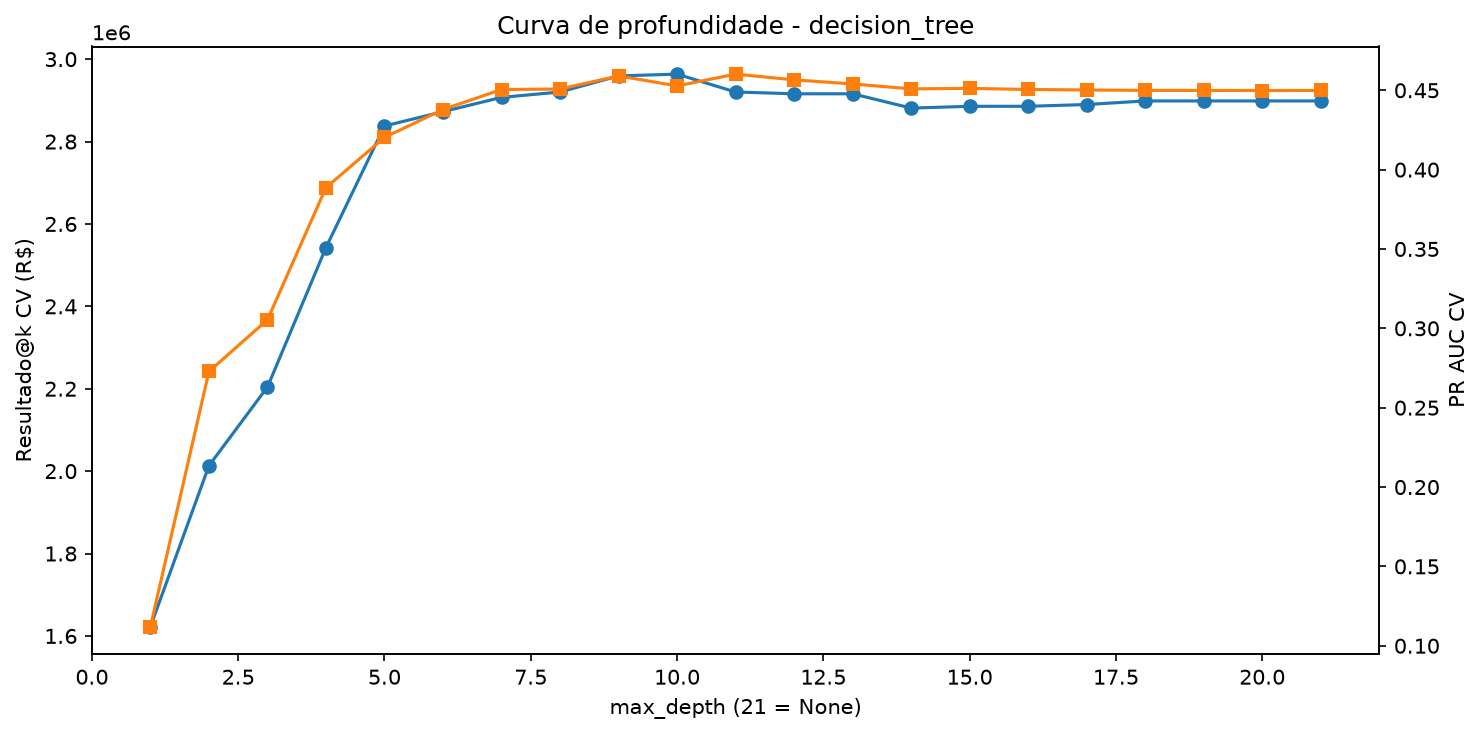

**04_02_random_forest_profundidade.png**

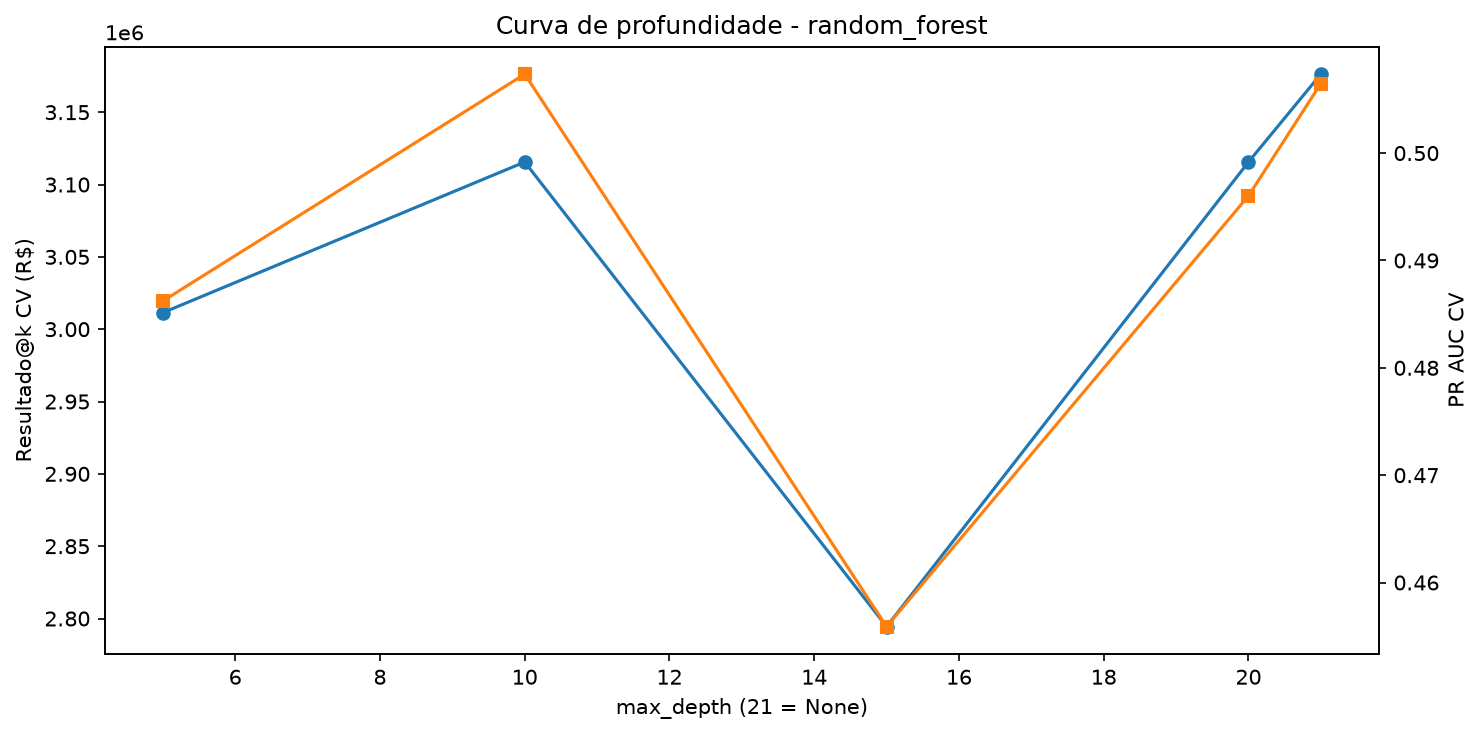

**parte5_curva_resultado_k.png**

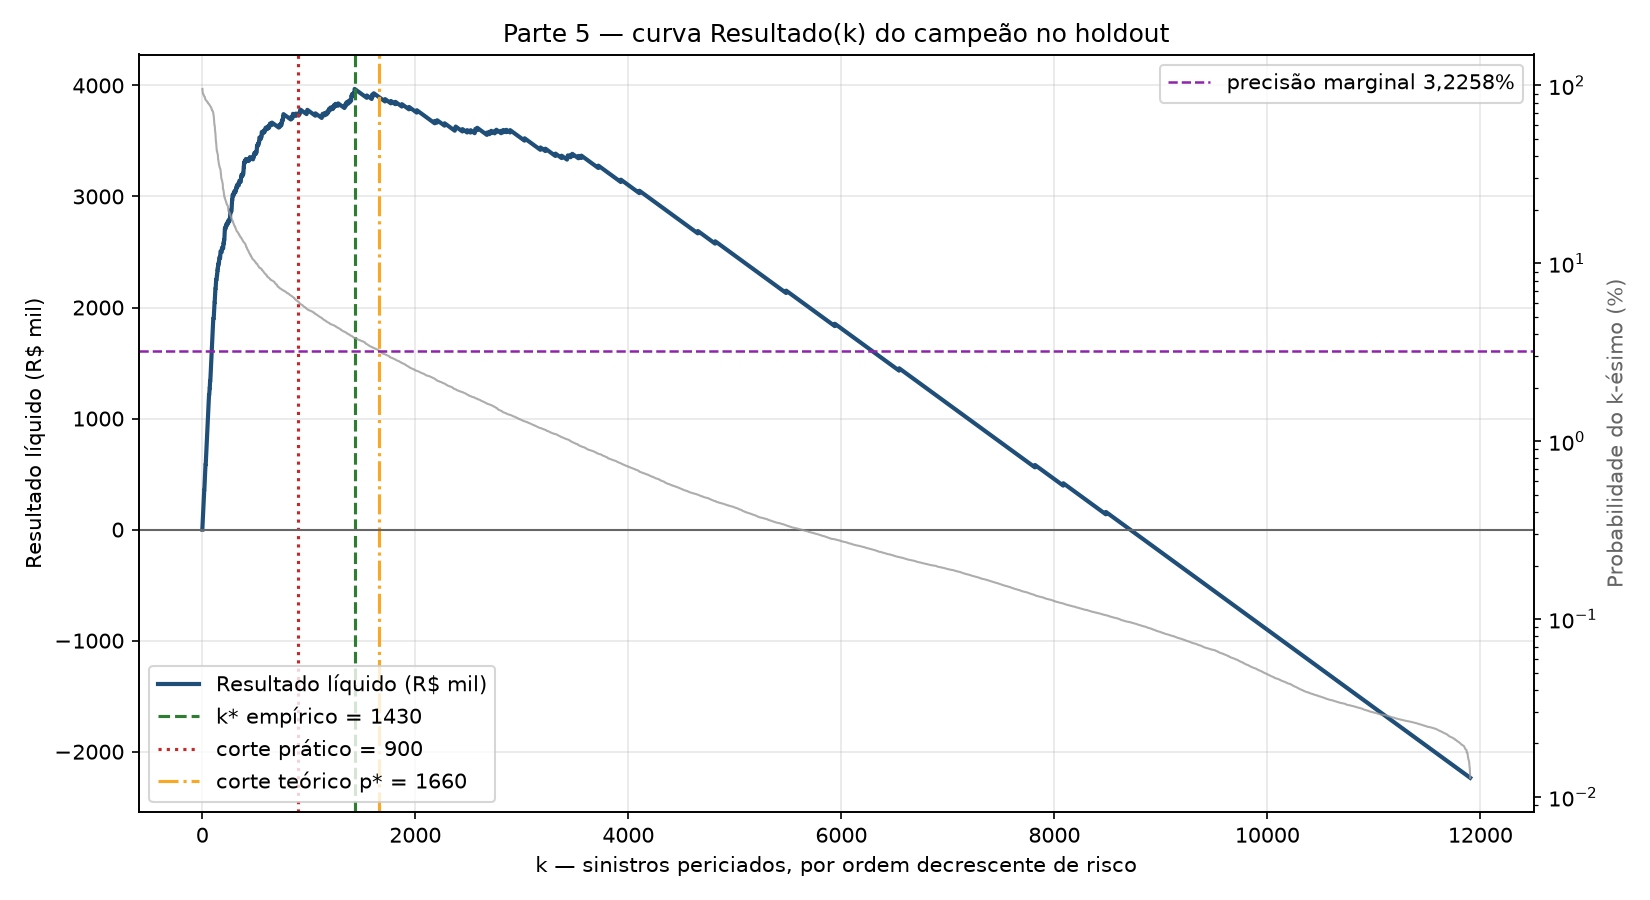

**parte5_calibracao.png**

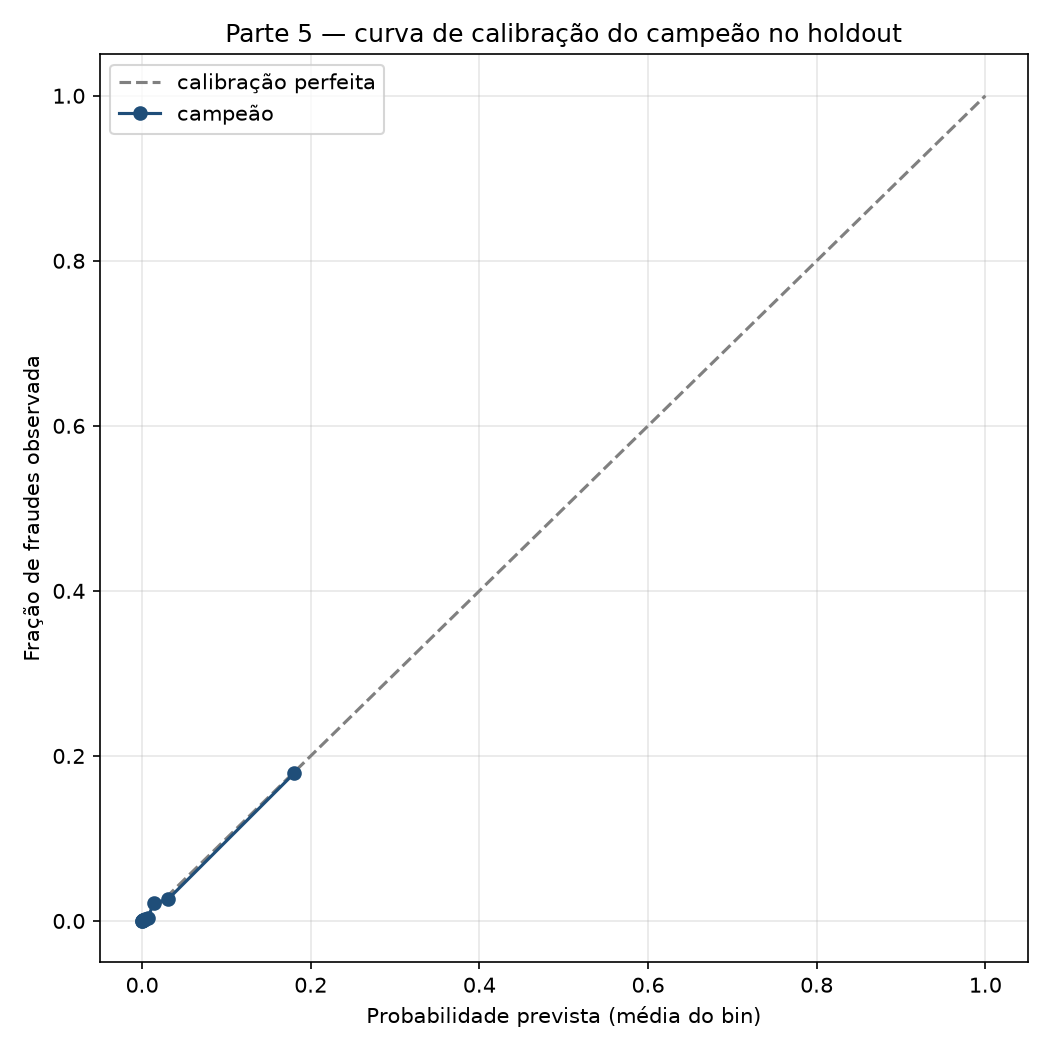

**parte5_shap_summary.png**

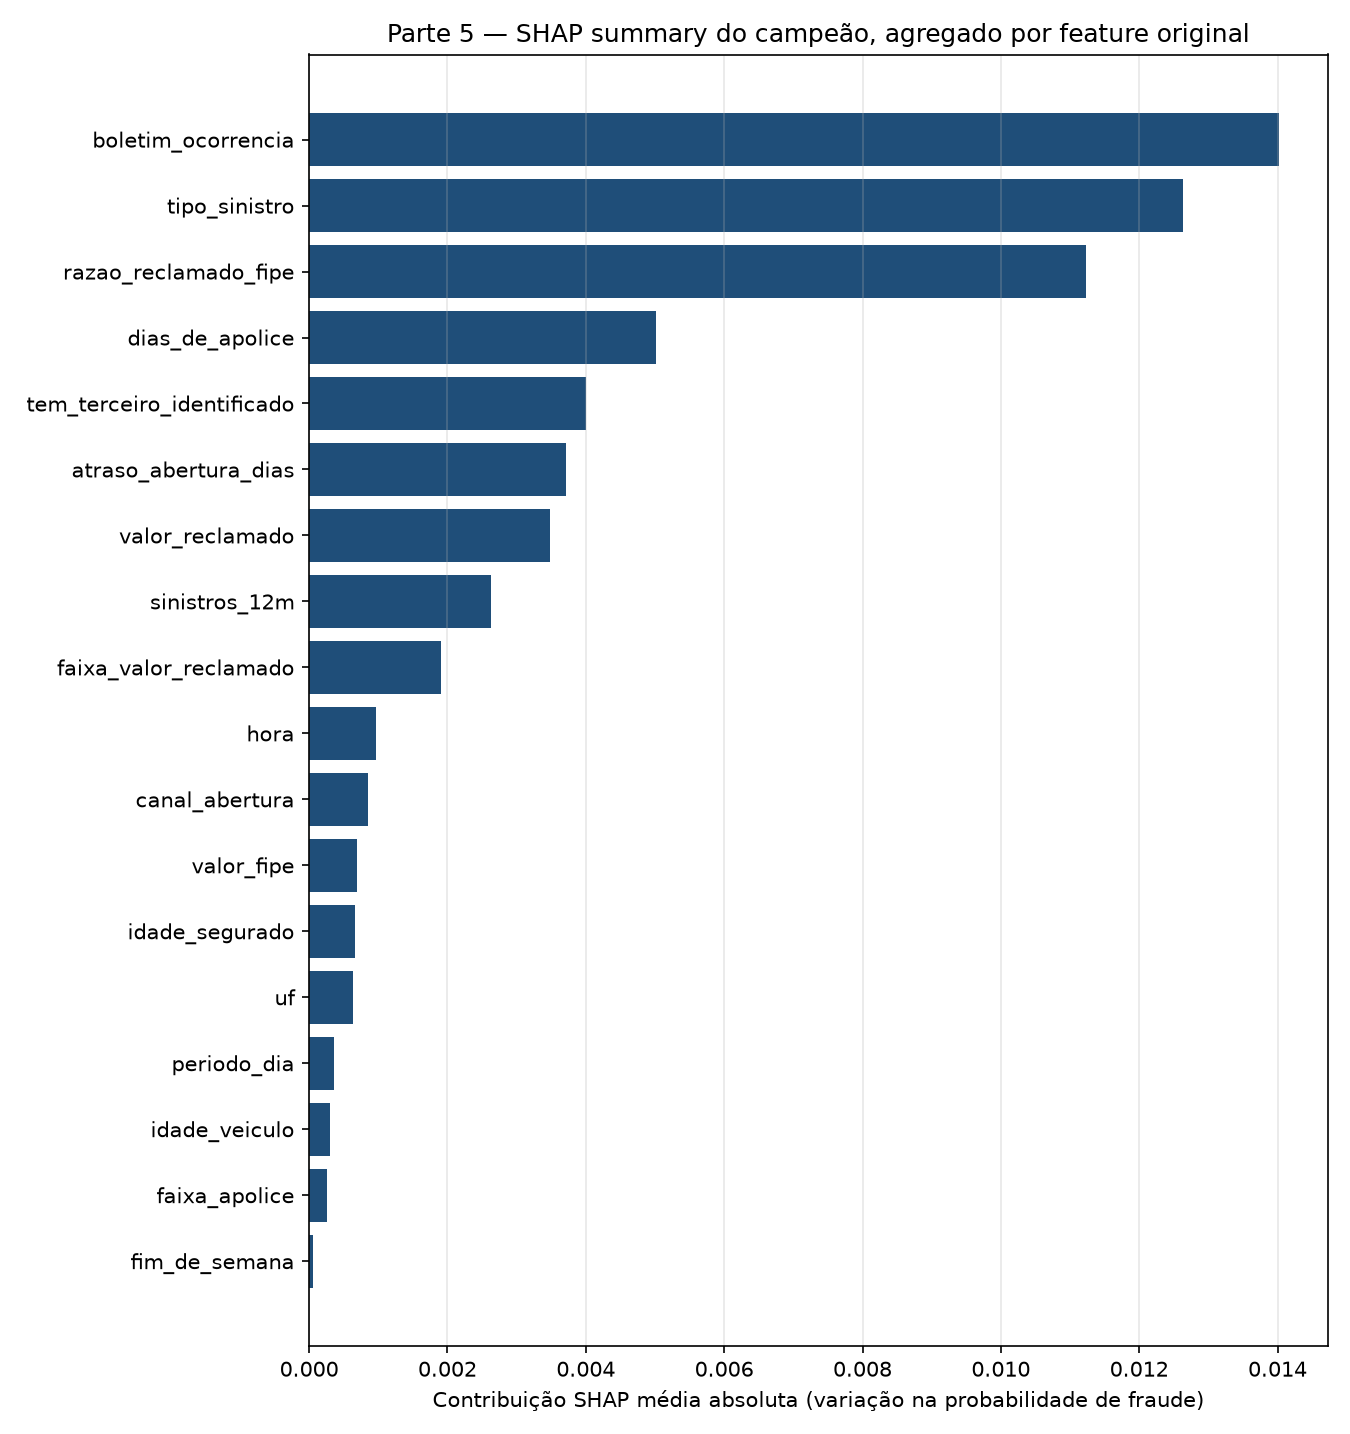

**parte5_shap_local_fraude_pega.png**

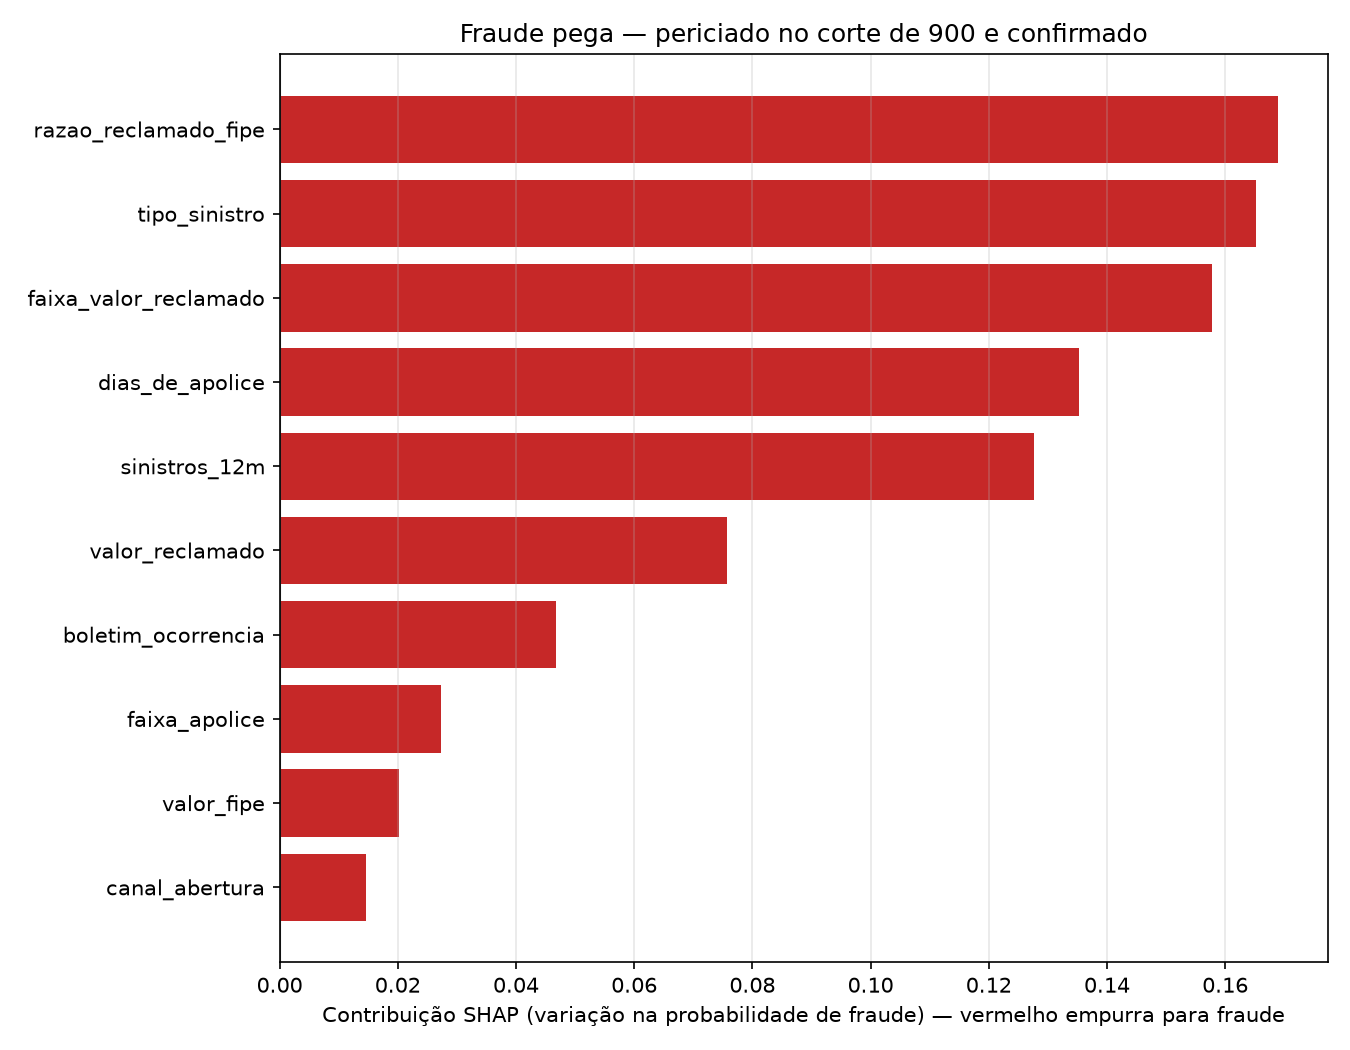

**parte5_shap_local_fraude_perdida.png**

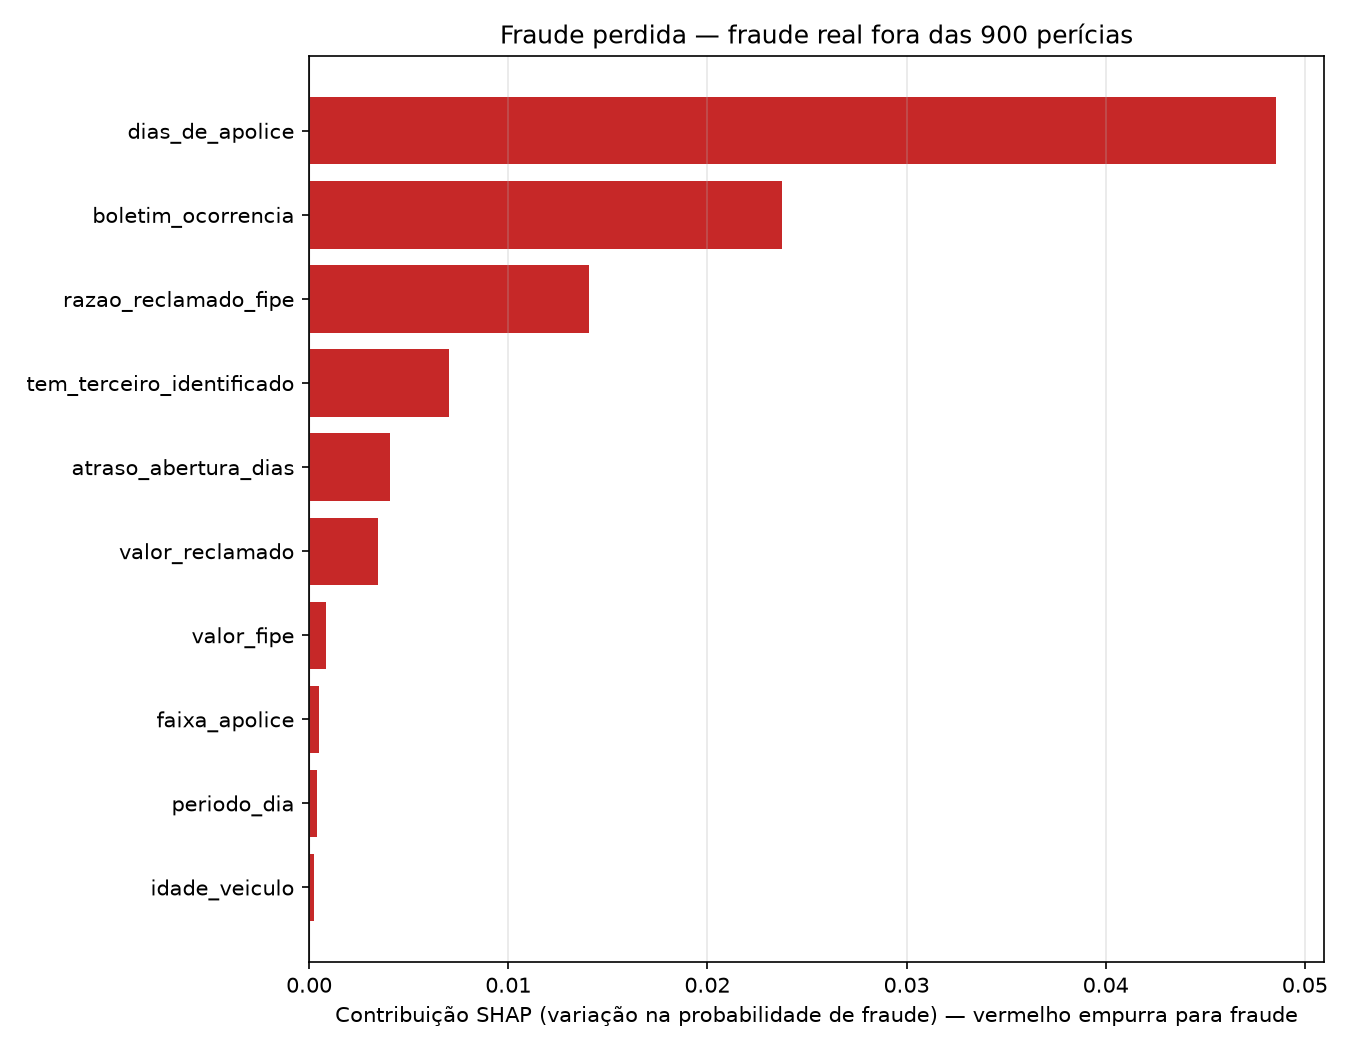

**parte5_shap_local_legitimo_topo.png**

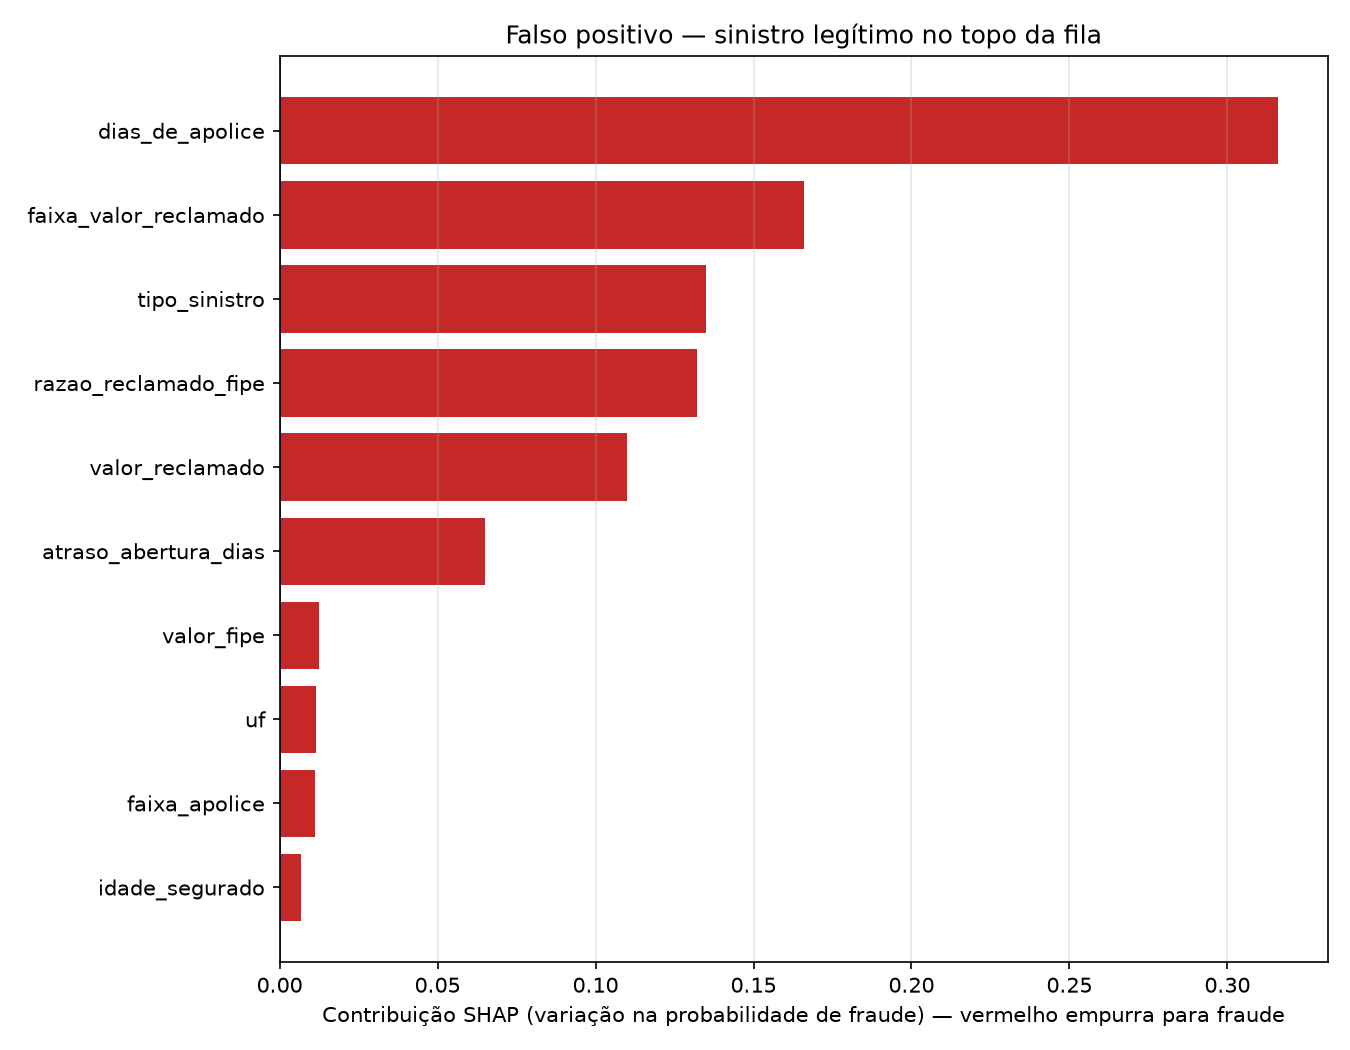

In [4]:
print("Decomposição da função de custo por família e por corte:")
display(custo_familias)
print("Robustez do campeão nas cinco sementes:")
display(sementes_campeao)
print("Calibração:")
display(calibracao)
print("Ablação:")
display(ablacao)
print("Casos SHAP locais:")
display(casos_shap)
print("Importância SHAP agregada por feature original:")
display(importancia_shap.head(10))

figuras = [
    "04_01_decision_tree_profundidade.png",
    "04_02_random_forest_profundidade.png",
    "parte5_curva_resultado_k.png",
    "parte5_calibracao.png",
    "parte5_shap_summary.png",
    "parte5_shap_local_fraude_pega.png",
    "parte5_shap_local_fraude_perdida.png",
    "parte5_shap_local_legitimo_topo.png",
]
for nome_figura in figuras:
    caminho_figura = RAIZ / "reports" / "figures" / nome_figura
    if caminho_figura.exists():
        display(Markdown(f"**{nome_figura}**"))
        display(Image(filename=str(caminho_figura)))

## 4. Reajuste final, holdout e artefato do aplicativo

Só depois de fechar CV, busca, amostragem e seleção do campeão acessamos o
holdout temporal. O campeão continua sendo escolhido pelo ranking versionado;
o Pipeline completo é então ajustado nos quatro meses de treino e testado uma
única vez em agosto.

In [5]:
campeao = ranking_candidatos.iloc[0]
assert campeao["familia_modelo"] == "xgboost"
assert campeao["estrategia"] == "controle"

del base_crua_treino, base_treino_cv, X_treino_cv, y_treino_cv
X_treino, y_treino, X_teste, y_teste = carregar_treino_teste()

with contexto_run(
    nome=nome_run("xgboost", "parte6_integracao", SEED),
    parametros={
        "familia_modelo": str(campeao["familia_modelo"]),
        "estrategia_amostragem": str(campeao["estrategia"]),
        "seed": SEED,
        "capacidade_mensal": CAPACIDADE_MENSAL,
        "limiar_corte_teorico": LIMIAR_CORTE_TEORICO,
        **dict(campeao["parametros_modelo"]),
    },
    tags={"fase": "4", "parte": "6", "modelo": "xgboost", "papel": "integracao_campeao"},
) as registro_campeao:
    pipeline_campeao = ajustar_candidato(campeao, X_treino, y_treino, seed=SEED)
    probabilidades_holdout = pipeline_campeao.predict_proba(X_teste)[:, 1]
    metricas_holdout = calcular_metricas_holdout(y_teste, probabilidades_holdout)
    registro_campeao.log_metricas(metricas_holdout, prefixo="holdout_")
    registro_campeao.log_json(metricas_holdout, "metricas_holdout.json")
    uri_modelo = registro_campeao.log_pipeline(pipeline_campeao, X_treino.head(1))
    versao_registro = registro_campeao.registrar_modelo(
        NOME_MODELO_REGISTRADO,
        descricao=(
            "Campeao da Fase 4: XGBoost controle, selecionado por Resultado Liquido@900."
        ),
        tags={"fase": "4", "parte": "6", "familia_modelo": "xgboost"},
        alias=ALIAS_CAMPEAO,
    )

caminho_salvo = salvar_pipeline(pipeline_campeao)
pipeline_recarregado = carregar_pipeline(caminho_salvo)
probabilidades_recarregadas = pipeline_recarregado.predict_proba(X_teste)[:, 1]
np.testing.assert_allclose(
    probabilidades_recarregadas,
    probabilidades_holdout,
    rtol=0,
    atol=1e-12,
)

print(f"Campeão: {campeao['familia_modelo']} / {campeao['estrategia']}")
print(f"Run de integração: {registro_campeao.run_id}")
print(f"URI resolvível do modelo logado: {uri_modelo}")
print(f"Registro: {NOME_MODELO_REGISTRADO} | alias={ALIAS_CAMPEAO} | versão={versao_registro}")
print(f"Artefato regravado: {caminho_salvo.relative_to(RAIZ)}")
print(f"Tamanho do artefato: {caminho_salvo.stat().st_size:,} bytes")
print(f"Paridade antes/depois da recarga: {np.max(np.abs(probabilidades_holdout - probabilidades_recarregadas)):.2e}")
display(pd.DataFrame([metricas_holdout]))

2026/11/07 12:17:40 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


2026/11/07 12:17:44 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


Registered model 'quilha-fraude-campeao' already exists. Creating a new version of this model...
Created version '4' of model 'quilha-fraude-campeao'.


Campeão: xgboost / controle
Run de integração: e4237e7b4ce747679b76181c648b3e06
URI resolvível do modelo logado: models:/m-1d80792f1207493eaa934077974c3cf6
Registro: quilha-fraude-campeao | alias=champion | versão=4
Artefato regravado: models\pipeline_fraude.joblib
Tamanho do artefato: 449,791 bytes
Paridade antes/depois da recarga: 0.00e+00


,pr_auc,roc_auc,brier,precisao_900,cobertura_900,resultado_900,custo_total_900,tp_900,fp_900,fn_900
0,0.538556,0.936597,0.014702,0.223333,0.715302,3731700.0,2225300.0,201,699,80


## 5. Critérios de integração

O teste automatizado cobre o scorer financeiro, a Regra Atual, o corte teórico,
`k` proporcional e a paridade de predição do artefato salvo. A checagem final
abaixo confirma que o modelo carregado pelo aplicativo é o XGBoost campeão e
que todos os três componentes do Pipeline estão presentes.

In [6]:
assert list(pipeline_recarregado.named_steps) == ["preparo", "imputacao", "modelo"]
assert type(pipeline_recarregado.named_steps["modelo"]).__name__ == "XGBClassifier"
assert len(tabela_cv_modelos) == 6
assert tabela_cv_modelos["k_fold"].nunique() == 1
assert int(tabela_cv_modelos["k_fold"].iloc[0]) == 720
assert int(metricas_holdout["tp_900"]) == 201
assert int(metricas_holdout["fp_900"]) == 699
assert int(metricas_holdout["fn_900"]) == 80
assert float(metricas_holdout["resultado_900"]) == 3_731_700.0
print("ACEITE: seis modelos com CV comparável; Pipeline campeão salvo e validado.")

ACEITE: seis modelos com CV comparável; Pipeline campeão salvo e validado.
